In [1]:
import seaborn as sns
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import pandas as pd
import torch
import numpy as np
from utils import *
import h5py
sns.set_style("whitegrid")
LABEL_FONTSIZE = 6
TICK_FONTSIZE = 6
LEGEND_FONTSIZE = 6
FIGSIZE = (3, 2)

MARKERSIZE = 5
LINEWIDTH = 0.8
ALPHA = 1.0
SPINE_WIDTH = 0.7
SPINE_COLOR = 'gray'
TICK_COLOR = 'gray'

GRID_ALPHA = 0.1
GRID_LINESTYLE = '--'
GRID_LINEWIDTH = 0.5
palette = plt.cm.tab10.colors
palette_subset = [palette[7], palette[8], palette[9]]

cell_colors = {
        'Immune': palette[0],
        'Str': palette[1],
        'Pod': palette[2],
        'CD': palette[3],
        'PE': palette[4],
        'Tcell': palette[5],
        'END': palette[6],  
        'DT': palette[7],
        'PT': palette[8],
        'LOH': palette[9]
  }


# Figure 5

In [41]:
models=['insert_n_4k_n', 'insert_n_8k_n', 'insert_n_16k_n', 'insert_n_32k_n','insert_n_64k_n','insert_n_128k_n', 'insert_n_256k_n','insert_full']
cell_ids = ['Immune', 'Str', 'Pod', 'CD', 'PE', 'Tcell', 'END', 'DT', 'PT', 'LOH']
data_dir = "ubiquitous_and_cell_specific_targets/ubiquitous/"

results = {}
for model in models:
    
    pred_path = f"ubiquitous_and_cell_specific_targets/with_ns/{model}/ubiquitous.pt"
    cells = ['Immune', 'stromal', 'Podocyte', 'CD', 'PE', 'Tcell', 'END', 'DT', 'PT', 'LOH']
    
    corrs_df = compute_ubiquitous_correlations(
        data_dir=data_dir,
        predictions_path=pred_path,
        cells=cells,
        n_cell_ids=10,
        pred_slice=(4, 12)
    )
    corrs_df.columns = cells
    corrs_df.index = cells
    results[model] = corrs_df

ubiquitous_results_bor = {}
for model in models:
    res = results[model]
    for i, cell in enumerate(cell_ids):
        ubiquitous_results_bor[f'{model}_{cell}' ] = res.iloc[i,i]

Immune - cell_0: Pearson r = 0.636
Immune - cell_1: Pearson r = 0.548
Immune - cell_2: Pearson r = 0.507
Immune - cell_3: Pearson r = 0.508
Immune - cell_4: Pearson r = 0.526
Immune - cell_5: Pearson r = 0.574
Immune - cell_6: Pearson r = 0.587
Immune - cell_7: Pearson r = 0.502
Immune - cell_8: Pearson r = 0.516
Immune - cell_9: Pearson r = 0.493
stromal - cell_0: Pearson r = 0.475
stromal - cell_1: Pearson r = 0.591
stromal - cell_2: Pearson r = 0.490
stromal - cell_3: Pearson r = 0.418
stromal - cell_4: Pearson r = 0.469
stromal - cell_5: Pearson r = 0.452
stromal - cell_6: Pearson r = 0.506
stromal - cell_7: Pearson r = 0.435
stromal - cell_8: Pearson r = 0.415
stromal - cell_9: Pearson r = 0.430
Podocyte - cell_0: Pearson r = 0.464
Podocyte - cell_1: Pearson r = 0.479
Podocyte - cell_2: Pearson r = 0.554
Podocyte - cell_3: Pearson r = 0.453
Podocyte - cell_4: Pearson r = 0.502
Podocyte - cell_5: Pearson r = 0.462
Podocyte - cell_6: Pearson r = 0.465
Podocyte - cell_7: Pearson r = 

In [42]:

data = {}
for key, value in ubiquitous_results_bor.items():

    model, cell = key.rsplit('_', 1) 
    
    if model not in data:

        data[model] = {}        
    data[model][cell] = value

def extract_length(model_name):
    
    if 'full' in model_name:
        return 'Full'
    
    return model_name.split('_')[2] 

df = pd.DataFrame(data).T

df.index.name = 'Model'
df['Model'] = df.index.map(extract_length)
df_melted = df.reset_index(drop=True).melt(
    id_vars='Model',
    var_name='Cell Type',
    value_name='Performance'
)

SEQUENCE_ORDER = ['4k', '8k', '16k', '32k', '64k', '128k', '256k', 'Full']

df_melted['Model'] = pd.Categorical(
    df_melted['Model'],
    categories=SEQUENCE_ORDER,
    ordered=True
)

df_melted = df_melted.sort_values('Model')
df_melted['Model'] = df_melted['Model'].str.replace('k', 'kbp', regex=False)

In [45]:
df.round(3)

,Immune,Str,Pod,CD,PE,Tcell,END,DT,PT,LOH,Model
Model,,,,,,,,,,,
insert_n_4k_n,0.636,0.591,0.554,0.633,0.483,0.647,0.603,0.633,0.614,0.607,4k
insert_n_8k_n,0.662,0.616,0.560,0.638,0.501,0.681,0.627,0.642,0.619,0.609,8k
insert_n_16k_n,0.703,0.659,0.578,0.664,0.535,0.715,0.657,0.671,0.641,0.638,16k
insert_n_32k_n,0.753,0.697,0.603,0.704,0.585,0.755,0.698,0.712,0.675,0.681,32k
insert_n_64k_n,0.790,0.724,0.624,0.726,0.633,0.784,0.731,0.738,0.708,0.712,64k
insert_n_128k_n,0.817,0.752,0.641,0.743,0.664,0.803,0.757,0.753,0.737,0.730,128k
insert_n_256k_n,0.832,0.772,0.654,0.756,0.691,0.818,0.778,0.766,0.760,0.751,256k
insert_full,0.837,0.782,0.665,0.764,0.702,0.824,0.786,0.774,0.770,0.761,Full


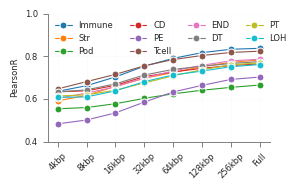

In [7]:
fig, ax = plt.subplots(figsize=FIGSIZE)

sns.lineplot(
    data=df_melted,
    x='Model',
    y='Performance',
    hue='Cell Type',
    hue_order=list(cell_colors.keys()),
    marker='o',
    markersize=MARKERSIZE,
    linewidth=LINEWIDTH,
    alpha=ALPHA,
    palette=cell_colors,
    ax=ax
)

ax.set_xlabel('')
ax.set_ylabel('PearsonR', fontsize=LABEL_FONTSIZE)

# Ticks
ax.tick_params(
    axis='both',
    which='major',
    labelsize=TICK_FONTSIZE,
    width=SPINE_WIDTH,
    color=TICK_COLOR,
    bottom=True,
    left=True,
    top=False,
    right=False
)
plt.xticks(rotation=45)


ax.set_ylim(0.4, 1.0)
plt.yticks([0.4, 0.6, 0.8, 1.0])
ax.legend(
    title='',
    fontsize=LEGEND_FONTSIZE,
    frameon=False,
    shadow=True,
    loc='upper left',
    ncol=4
)

for spine in ['left', 'bottom']:
    ax.spines[spine].set_linewidth(SPINE_WIDTH)
    ax.spines[spine].set_color(SPINE_COLOR)


ax.grid(
    True,
    alpha=GRID_ALPHA,
    linestyle=GRID_LINESTYLE,
    linewidth=GRID_LINEWIDTH
)

sns.despine(top=True, right=True, left=False, bottom=False)
plt.tight_layout()
plt.show()

# cell specific

In [8]:
models=['insert_n_4k_n', 'insert_n_8k_n','insert_n_16k_n', 'insert_n_32k_n','insert_n_64k_n','insert_n_128k_n', 'insert_n_256k_n', 'insert_full']
data_dir = "ubiquitous_and_cell_specific_targets/cell_specific_bed/"
cells_bed = ['Immune', 'stromal', 'Podocyte', 'CD', 'PE', 'Tcell', 'END', 'DT', 'PT', 'LOH']

cells_pred = [
    'Immune_predictions',
    'stromal_predictions',
    'Podocyte_predictions',
    'CD_predictions',
    'PE_predictions',
    'Tcell_predictions',
    'END_predictions',
    'DT_predictions',
    'PT_predictions',
    'LOH_predictions'
]

results = {}

for model in models:
    
    pred_dir = f"ubiquitous_and_cell_specific_targets/with_ns/{model}/cell_specific"
    cells = ['Immune', 'stromal', 'Podocyte', 'CD', 'PE', 'Tcell', 'END', 'DT', 'PT', 'LOH']
    
    corrs_df = compute_cell_specific_correlations(
    target_dir = data_dir ,
    pred_dir= pred_dir,
    cells_bed=cells_bed, 
    cells_pred=cells_pred,
    n_cell_ids=10,
    pred_slice=(4, 12)
)
    corrs_df.columns = cells
    corrs_df.index = cells
    results[model] = corrs_df

cell_specific_results = {}
for model in models:
    res = results[model]
    for i, cell in enumerate(cell_ids):
        cell_specific_results[f'{model}_{cell}' ] = res.iloc[i,i]

Immune | cell_0: r = 0.305
Immune | cell_1: r = 0.049
Immune | cell_2: r = -0.148
Immune | cell_3: r = 0.026
Immune | cell_4: r = -0.027
Immune | cell_5: r = -0.043
Immune | cell_6: r = 0.074
Immune | cell_7: r = 0.060
Immune | cell_8: r = 0.033
Immune | cell_9: r = 0.070
stromal | cell_0: r = 0.031
stromal | cell_1: r = 0.323
stromal | cell_2: r = -0.042
stromal | cell_3: r = 0.063
stromal | cell_4: r = 0.006
stromal | cell_5: r = -0.003
stromal | cell_6: r = 0.051
stromal | cell_7: r = 0.070
stromal | cell_8: r = 0.017
stromal | cell_9: r = 0.067
Podocyte | cell_0: r = 0.018
Podocyte | cell_1: r = 0.057
Podocyte | cell_2: r = 0.366
Podocyte | cell_3: r = 0.067
Podocyte | cell_4: r = 0.126
Podocyte | cell_5: r = 0.030
Podocyte | cell_6: r = 0.003
Podocyte | cell_7: r = 0.055
Podocyte | cell_8: r = 0.057
Podocyte | cell_9: r = 0.085
CD | cell_0: r = 0.028
CD | cell_1: r = 0.091
CD | cell_2: r = -0.071
CD | cell_3: r = 0.441
CD | cell_4: r = -0.057
CD | cell_5: r = 0.030
CD | cell_6: r 

In [26]:
data = {}
for key, value in cell_specific_results.items():

    model, cell = key.rsplit('_', 1) 
    
    if model not in data:
        data[model] = {}
        
    data[model][cell] = value


def extract_length(model_name):
    
    if 'full' in model_name:
        return 'Full'
    
    return model_name.split('_')[2] 

df = pd.DataFrame(data).T
df.index.name = 'Model'
df['Model'] = df.index.map(extract_length)
df_melted = df.reset_index(drop=True).melt(
    id_vars='Model',
    var_name='Cell Type',
    value_name='Performance'
)

df_melted['Model'] = pd.Categorical(
    df_melted['Model'],
    categories=SEQUENCE_ORDER,
    ordered=True
)

df_melted = df_melted.sort_values('Model')
df_melted['Model'] = df_melted['Model'].str.replace('k', 'kbp', regex=False)

In [36]:
df.round(3)

,Immune,Str,Pod,CD,PE,Tcell,END,DT,PT,LOH,Model
Model,,,,,,,,,,,
insert_n_4k_n,0.305,0.323,0.366,0.441,0.144,0.115,0.327,0.357,0.409,0.419,4k
insert_n_8k_n,0.314,0.339,0.364,0.473,0.159,0.161,0.348,0.362,0.408,0.422,8k
insert_n_16k_n,0.381,0.376,0.390,0.538,0.188,0.255,0.377,0.380,0.421,0.446,16k
insert_n_32k_n,0.467,0.412,0.427,0.587,0.222,0.382,0.415,0.401,0.459,0.491,32k
insert_n_64k_n,0.552,0.452,0.456,0.607,0.276,0.474,0.453,0.422,0.511,0.519,64k
insert_n_128k_n,0.618,0.490,0.479,0.615,0.326,0.535,0.506,0.426,0.557,0.529,128k
insert_n_256k_n,0.660,0.512,0.498,0.621,0.361,0.574,0.541,0.428,0.593,0.542,256k
insert_full,0.677,0.529,0.508,0.624,0.368,0.592,0.560,0.434,0.610,0.557,Full


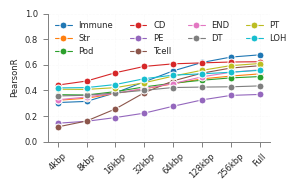

In [12]:

fig, ax = plt.subplots(figsize=FIGSIZE)

sns.lineplot(
    data=df_melted,
    x='Model',
    y='Performance',
    hue='Cell Type',
    hue_order=list(cell_colors.keys()),
    marker='o',
    markersize=MARKERSIZE,
    linewidth=LINEWIDTH,
    alpha=ALPHA,
    palette=cell_colors,
    ax=ax
)

ax.set_xlabel('')
ax.set_ylabel('PearsonR', fontsize=LABEL_FONTSIZE)

# Ticks
ax.tick_params(
    axis='both',
    which='major',
    labelsize=TICK_FONTSIZE,
    width=SPINE_WIDTH,
    color=TICK_COLOR,
    bottom=True,
    left=True,
    top=False,
    right=False
)
plt.xticks(rotation=45)

ax.set_ylim(0.0, 1.0)

ax.legend(
    title='',
    fontsize=LEGEND_FONTSIZE,
    frameon=False,
    shadow=True,
    loc='upper left',
    ncol=4
)

for spine in ['left', 'bottom']:
    ax.spines[spine].set_linewidth(SPINE_WIDTH)
    ax.spines[spine].set_color(SPINE_COLOR)


ax.grid(
    True,
    alpha=GRID_ALPHA,
    linestyle=GRID_LINESTYLE,
    linewidth=GRID_LINEWIDTH
)

# Clean up
sns.despine(top=True, right=True, left=False, bottom=False)

plt.tight_layout()
plt.show()


## Analysis with allelic imbalance

In [36]:
values = [4]
cells = {
    "DT": 7,
    "PT": 8,
    "LOH": 9
}

all_results ={}
ns_after_list = ["inser_ns_after_4k_rep0", "inser_ns_after_8k_rep0", "inser_ns_after_16k_rep0", "inser_ns_after_32k_rep0", "inser_ns_after_64k_rep0", 'inser_ns_after_128k_rep0', 'inser_ns_after_256k_rep0', 'rep0_all_bins_no_shifts']

for cell_name, cell_id in cells.items():
    all_results[cell_name] = {} 
    for ns_after in ns_after_list:

        print(f"Running for cell={cell_name}, cell_id={cell_id}, ns_after={ns_after}")

        pos_path = f"../caai_results/borzoi_finetuned_scoring/{ns_after}/{cell_name}/pos/sad.h5"
        neg_path = f"../caai_results/borzoi_finetuned_scoring/{ns_after}/{cell_name}/neg/sad.h5"

        pos_sad = h5py.File(pos_path, "r")
        neg_sad = h5py.File(neg_path, "r")
        results = sliding_caai_metrics(
            pos_sad,
            neg_sad,
            cell_id=cell_id,
            values=values
        )
        all_results[cell_name][ns_after] = results

        pos_sad.close()
        neg_sad.close()

        print(f"Finished: {cell_name}, ns_after={ns_after}")

Running for cell=DT, cell_id=7, ns_after=inser_ns_after_4k_rep0


/tmp/ipykernel_94408/2131777395.py:193: RuntimeWarning: invalid value encountered in divide
  neg_caai = neg_ref / (neg_ref + neg_alt + eps)


Finished: DT, ns_after=inser_ns_after_4k_rep0
Running for cell=DT, cell_id=7, ns_after=inser_ns_after_8k_rep0
Finished: DT, ns_after=inser_ns_after_8k_rep0
Running for cell=DT, cell_id=7, ns_after=inser_ns_after_16k_rep0
Finished: DT, ns_after=inser_ns_after_16k_rep0
Running for cell=DT, cell_id=7, ns_after=inser_ns_after_32k_rep0
Finished: DT, ns_after=inser_ns_after_32k_rep0
Running for cell=DT, cell_id=7, ns_after=inser_ns_after_64k_rep0
Finished: DT, ns_after=inser_ns_after_64k_rep0
Running for cell=DT, cell_id=7, ns_after=inser_ns_after_128k_rep0
Finished: DT, ns_after=inser_ns_after_128k_rep0
Running for cell=DT, cell_id=7, ns_after=inser_ns_after_256k_rep0
Finished: DT, ns_after=inser_ns_after_256k_rep0
Running for cell=DT, cell_id=7, ns_after=rep0_all_bins_no_shifts
Finished: DT, ns_after=rep0_all_bins_no_shifts
Running for cell=PT, cell_id=8, ns_after=inser_ns_after_4k_rep0
Finished: PT, ns_after=inser_ns_after_4k_rep0
Running for cell=PT, cell_id=8, ns_after=inser_ns_after_8k

/tmp/ipykernel_94408/2131777395.py:193: RuntimeWarning: invalid value encountered in divide
  neg_caai = neg_ref / (neg_ref + neg_alt + eps)


Finished: LOH, ns_after=inser_ns_after_4k_rep0
Running for cell=LOH, cell_id=9, ns_after=inser_ns_after_8k_rep0
Finished: LOH, ns_after=inser_ns_after_8k_rep0
Running for cell=LOH, cell_id=9, ns_after=inser_ns_after_16k_rep0
Finished: LOH, ns_after=inser_ns_after_16k_rep0
Running for cell=LOH, cell_id=9, ns_after=inser_ns_after_32k_rep0
Finished: LOH, ns_after=inser_ns_after_32k_rep0
Running for cell=LOH, cell_id=9, ns_after=inser_ns_after_64k_rep0
Finished: LOH, ns_after=inser_ns_after_64k_rep0
Running for cell=LOH, cell_id=9, ns_after=inser_ns_after_128k_rep0
Finished: LOH, ns_after=inser_ns_after_128k_rep0
Running for cell=LOH, cell_id=9, ns_after=inser_ns_after_256k_rep0
Finished: LOH, ns_after=inser_ns_after_256k_rep0
Running for cell=LOH, cell_id=9, ns_after=rep0_all_bins_no_shifts
Finished: LOH, ns_after=rep0_all_bins_no_shifts


In [37]:
ns_mapping = {
    "inser_ns_after_4k_rep0": "4kbp",
    "inser_ns_after_8k_rep0": "8kbp",
    "inser_ns_after_16k_rep0": "16kbp",
    "inser_ns_after_32k_rep0": "32kbp",
    "inser_ns_after_64k_rep0": "64kbp",
    "inser_ns_after_128k_rep0": "128kbp",
    "inser_ns_after_256k_rep0": "256kbp",
    "rep0_all_bins_no_shifts": "full"
}

data = {seq: [] for seq in SEQUENCE_ORDER}

for ns_after, seq_label in ns_mapping.items():
    dt_val  = all_results['DT'][ns_after]['auroc'][0]
    pt_val  = all_results['PT'][ns_after]['auroc'][0]
    loh_val = all_results['LOH'][ns_after]['auroc'][0]

    data[seq_label] = [float(dt_val), float(pt_val), float(loh_val)]


df = pd.DataFrame(data, index=['DT', 'PT', 'LOH']).T
df.index.name = 'Model'

df_melted = df.reset_index().melt(
    id_vars='Model',
    var_name='Type',
    value_name='AUROC'
)

df_melted['Model'] = pd.Categorical(
    df_melted['Model'],
    categories=SEQUENCE_ORDER,
    ordered=True
)



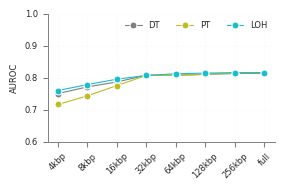

In [58]:
fig, ax = plt.subplots(figsize=FIGSIZE)

sns.lineplot(
    data=df_melted, x='Model', y='AUROC', hue='Type',
    marker='o', markersize=MARKERSIZE, linewidth=LINEWIDTH,
    palette=palette_subset, ax=ax, alpha=ALPHA
)

ax.set_xlabel('')

ax.set_ylabel('AUROC', fontsize=LABEL_FONTSIZE)
ax.set_ylim(0.6, 1.0)

plt.xticks(rotation=45)
plt.legend(title='', title_fontsize=LEGEND_FONTSIZE, fontsize=LEGEND_FONTSIZE,
           frameon=False, shadow=True, loc='upper right', ncol=3)

ax.spines['left'].set_linewidth(SPINE_WIDTH)
ax.spines['left'].set_color(SPINE_COLOR)
ax.spines['bottom'].set_linewidth(SPINE_WIDTH)
ax.spines['bottom'].set_color(SPINE_COLOR)

ax.tick_params(axis='both', which='major', labelsize=TICK_FONTSIZE,
               bottom=True, left=True, top=False, right=False, color=TICK_COLOR)

ax.grid(True, alpha=GRID_ALPHA, linestyle=GRID_LINESTYLE, linewidth=GRID_LINEWIDTH)

sns.despine(top=True, right=True, left=False, bottom=False)

plt.tight_layout()
plt.show()

In [42]:
data = {seq: [] for seq in SEQUENCE_ORDER}

for ns_after, seq_label in ns_mapping.items():
    dt_val  = all_results['DT'][ns_after]['auprc'][0]
    pt_val  = all_results['PT'][ns_after]['auprc'][0]
    loh_val = all_results['LOH'][ns_after]['auprc'][0]

    data[seq_label] = [float(dt_val), float(pt_val), float(loh_val)]

# Create dataframe
df = pd.DataFrame(data, index=['DT', 'PT', 'LOH']).T
df.index.name = 'Model'

# Melt for plotting
df_melted = df.reset_index().melt(
    id_vars='Model',
    var_name='Type',
    value_name='AUPRC'
)

df_melted['Model'] = pd.Categorical(
    df_melted['Model'],
    categories=SEQUENCE_ORDER,
    ordered=True
)



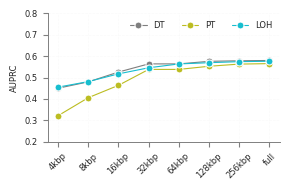

In [56]:
fig, ax = plt.subplots(figsize=FIGSIZE)

sns.lineplot(
    data=df_melted, x='Model', y='AUPRC', hue='Type',
    marker='o', markersize=MARKERSIZE, linewidth=LINEWIDTH,
    palette=palette_subset, ax=ax, alpha=ALPHA
)

ax.set_xlabel('')
ax.set_ylabel('AUPRC', fontsize=LABEL_FONTSIZE)
ax.set_ylim(0.2, 0.8)

plt.xticks(rotation=45)
#plt.yticks([0.6, 0.65, 0.7, 0.75, 0.8, 0.85])
plt.legend(title='', title_fontsize=LEGEND_FONTSIZE, fontsize=LEGEND_FONTSIZE,
           frameon=False, shadow=True, loc='upper right', ncol=3)

ax.spines['left'].set_linewidth(SPINE_WIDTH)
ax.spines['left'].set_color(SPINE_COLOR)
ax.spines['bottom'].set_linewidth(SPINE_WIDTH)
ax.spines['bottom'].set_color(SPINE_COLOR)

ax.tick_params(axis='both', which='major', labelsize=TICK_FONTSIZE,
               bottom=True, left=True, top=False, right=False, color=TICK_COLOR)

ax.grid(True, alpha=GRID_ALPHA, linestyle=GRID_LINESTYLE, linewidth=GRID_LINEWIDTH)

sns.despine(top=True, right=True, left=False, bottom=False)

plt.tight_layout()
plt.show()

# analysis with finemapping

In [5]:
score_dir = "results/fine_mapped/"
values= [16]
cells= {
    'immune': 0,
    'str': 1,
    'pod': 2,
    'CD': 3,
    'PE': 4,
    'tcell': 5,
    'end': 6,
    'dt': 7,
    'pt': 8,
    'loh': 9
}

ns_after_list = ["insert_ns_after_4k", "insert_ns_after_8k", "insert_ns_after_16k", "insert_ns_after_32k", "insert_ns_after_64k",'insert_ns_after_128k','insert_ns_after_256k','full']
all_results = {} 

for cell_name, cell_id in cells.items():
    all_results[cell_name] = {} 
    for ns_after in ns_after_list:

        print(f"Running for cell={cell_name}, cell_id={cell_id}, ns_after={ns_after}")

        pos_path = f"{score_dir}/with_ns_new/pos/{ns_after}/sad.h5"
        neg_path = f"{score_dir}/with_ns_new/neg/{ns_after}/sad.h5"

        pos_sad = h5py.File(pos_path, "r")
        neg_sad = h5py.File(neg_path, "r")

        seq_len = neg_sad['REF'].shape[1]

        
        results = sliding_sad_metrics(
                            pos_sad,
                            neg_sad,
                            cell_id,
                            values
                        )

        all_results[cell_name][ns_after] = results

        
        print(f"Finished: {cell_name}, ns_after={ns_after}")


Running for cell=immune, cell_id=0, ns_after=insert_ns_after_4k
Finished: immune, ns_after=insert_ns_after_4k
Running for cell=immune, cell_id=0, ns_after=insert_ns_after_8k
Finished: immune, ns_after=insert_ns_after_8k
Running for cell=immune, cell_id=0, ns_after=insert_ns_after_16k
Finished: immune, ns_after=insert_ns_after_16k
Running for cell=immune, cell_id=0, ns_after=insert_ns_after_32k
Finished: immune, ns_after=insert_ns_after_32k
Running for cell=immune, cell_id=0, ns_after=insert_ns_after_64k
Finished: immune, ns_after=insert_ns_after_64k
Running for cell=immune, cell_id=0, ns_after=insert_ns_after_128k
Finished: immune, ns_after=insert_ns_after_128k
Running for cell=immune, cell_id=0, ns_after=insert_ns_after_256k
Finished: immune, ns_after=insert_ns_after_256k
Running for cell=immune, cell_id=0, ns_after=full
Finished: immune, ns_after=full
Running for cell=str, cell_id=1, ns_after=insert_ns_after_4k
Finished: str, ns_after=insert_ns_after_4k
Running for cell=str, cell_id=

In [27]:
rows = []
for cell_type, models in all_results.items():
    for model, metrics in models.items():
        rows.append({
            "Cell": cell_type,
            "Model": model,
            "Num": metrics["num"][0],
            "AUROC": metrics["auroc"][0],
            "AUPRC": metrics["auprc"][0]
        })

df = pd.DataFrame(rows)
df

,Cell,Model,Num,AUROC,AUPRC
0,immune,insert_ns_after_4k,16,0.588083,0.259142
1,immune,insert_ns_after_8k,16,0.614282,0.279114
2,immune,insert_ns_after_16k,16,0.642835,0.308904
3,immune,insert_ns_after_32k,16,0.675975,0.332094
4,immune,insert_ns_after_64k,16,0.693898,0.336621
...,...,...,...,...,...
75,loh,insert_ns_after_32k,16,0.755616,0.463866
76,loh,insert_ns_after_64k,16,0.759228,0.460364
77,loh,insert_ns_after_128k,16,0.772436,0.457959
78,loh,insert_ns_after_256k,16,0.783192,0.460415


In [28]:
model_order = [
    'insert_ns_after_4k',
    'insert_ns_after_8k',
    'insert_ns_after_16k',
    'insert_ns_after_32k',
    'insert_ns_after_64k',
    'insert_ns_after_128k',
    'insert_ns_after_256k',
    'full'
]

cell_order = [
    'immune', 'str', 'pod', 'CD', 'PE',
    'tcell', 'end', 'dt', 'pt', 'loh'
]

model_map = {
    'insert_ns_after_4k': '4k',
    'insert_ns_after_8k': '8k',
    'insert_ns_after_16k': '16k',
    'insert_ns_after_32k': '32k',
    'insert_ns_after_64k': '64k',
    'insert_ns_after_128k': '128k',
    'insert_ns_after_256k': '256k',
    'full': 'Full'
}

df_auroc = (
    df.pivot(index='Model', columns='Cell', values='AUROC')
      .reindex(model_order)          
      .reindex(columns=cell_order)   
      .rename(columns={
          'immune': 'Immune',
          'str': 'Str',
          'pod': 'Pod',
          'CD': 'CD',
          'PE': 'PE',
          'tcell': 'Tcell',
          'end': 'END',
          'dt': 'DT',
          'pt': 'PT',
          'loh': 'LOH'
      })
      .reset_index()
)

df_auroc['Context'] = df_auroc['Model'].map(model_map)
df_auroc.round(3)

Cell,Model,Immune,Str,Pod,CD,PE,Tcell,END,DT,PT,LOH,Context
0,insert_ns_after_4k,0.588,0.675,0.658,0.663,0.705,0.596,0.621,0.699,0.671,0.686,4k
1,insert_ns_after_8k,0.614,0.695,0.661,0.689,0.717,0.625,0.647,0.722,0.692,0.710,8k
2,insert_ns_after_16k,0.643,0.711,0.701,0.717,0.735,0.654,0.672,0.736,0.703,0.739,16k
3,insert_ns_after_32k,0.676,0.731,0.731,0.749,0.762,0.667,0.704,0.755,0.734,0.756,32k
4,insert_ns_after_64k,0.694,0.762,0.737,0.763,0.771,0.688,0.726,0.761,0.749,0.759,64k
5,insert_ns_after_128k,0.699,0.768,0.745,0.765,0.778,0.704,0.746,0.767,0.764,0.772,128k
6,insert_ns_after_256k,0.710,0.771,0.739,0.768,0.781,0.710,0.753,0.771,0.777,0.783,256k
7,full,0.709,0.770,0.747,0.766,0.777,0.711,0.755,0.776,0.777,0.783,Full


In [29]:
df_auprc = (
    df.pivot(index='Model', columns='Cell', values='AUPRC')
      .reindex(model_order)          
      .reindex(columns=cell_order)  
      .rename(columns={
          'immune': 'Immune',
          'str': 'Str',
          'pod': 'Pod',
          'CD': 'CD',
          'PE': 'PE',
          'tcell': 'Tcell',
          'end': 'END',
          'dt': 'DT',
          'pt': 'PT',
          'loh': 'LOH'
      })
      .reset_index()
)

df_auprc['Context'] = df_auprc['Model'].map(model_map)
df_auprc.round(3)

Cell,Model,Immune,Str,Pod,CD,PE,Tcell,END,DT,PT,LOH,Context
0,insert_ns_after_4k,0.259,0.373,0.330,0.371,0.401,0.266,0.292,0.409,0.372,0.412,4k
1,insert_ns_after_8k,0.279,0.387,0.335,0.396,0.417,0.296,0.317,0.430,0.397,0.429,8k
2,insert_ns_after_16k,0.309,0.402,0.365,0.417,0.424,0.319,0.351,0.436,0.411,0.448,16k
3,insert_ns_after_32k,0.332,0.409,0.376,0.438,0.445,0.331,0.369,0.451,0.442,0.464,32k
4,insert_ns_after_64k,0.337,0.417,0.374,0.439,0.448,0.337,0.379,0.446,0.446,0.460,64k
5,insert_ns_after_128k,0.329,0.411,0.374,0.430,0.448,0.342,0.382,0.445,0.447,0.458,128k
6,insert_ns_after_256k,0.328,0.409,0.369,0.429,0.452,0.346,0.385,0.446,0.448,0.460,256k
7,full,0.331,0.406,0.371,0.431,0.448,0.344,0.384,0.447,0.445,0.460,Full


In [22]:
ns_mapping = {
    "insert_ns_after_4k": "4kbp",
    "insert_ns_after_8k": "8kbp",
    "insert_ns_after_16k": "16kbp",
    "insert_ns_after_32k": "32kbp",
    "insert_ns_after_64k": "64kbp",
    "insert_ns_after_128k": "128kbp",
    "insert_ns_after_256k": "256kbp",
    "full": "full"
}

data = {seq: [] for seq in SEQUENCE_ORDER}

for ns_after, seq_label in ns_mapping.items():
    imm_val  = all_results['immune'][ns_after]['auroc'][0]
    str_val  = all_results['str'][ns_after]['auroc'][0]
    pod_val  = all_results['pod'][ns_after]['auroc'][0]
    cd_val = all_results['CD'][ns_after]['auroc'][0]
    pe_val  = all_results['PE'][ns_after]['auroc'][0]
    tcell_val  = all_results['tcell'][ns_after]['auroc'][0]
    end_val = all_results['end'][ns_after]['auroc'][0]
    dt_val  = all_results['dt'][ns_after]['auroc'][0]
    pt_val  = all_results['pt'][ns_after]['auroc'][0]
    loh_val = all_results['loh'][ns_after]['auroc'][0]

    data[seq_label] = [float(imm_val), float(str_val), float(pod_val), float(cd_val),float(pe_val), float(tcell_val), float(end_val),float(dt_val), float(pt_val), float(loh_val)]

# Create dataframe
df = pd.DataFrame(data, index=['Immune','Str', 'Pod', 'CD', 'PE', 'Tcell', 'End',  'DT', 'PT', 'LOH']).T
df.index.name = 'Model'

# Melt for plotting
df_melted = df.reset_index().melt(
    id_vars='Model',
    var_name='Type',
    value_name='AUROC'
)

df_melted['Model'] = pd.Categorical(
    df_melted['Model'],
    categories=SEQUENCE_ORDER,
    ordered=True
)

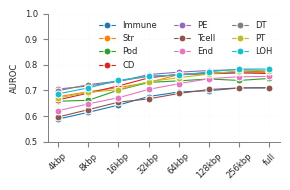

In [23]:
fig, ax = plt.subplots(figsize=FIGSIZE)

sns.lineplot(
    data=df_melted, x='Model', y='AUROC', hue='Type',
    marker='o', markersize=MARKERSIZE, linewidth=LINEWIDTH,
    palette=palette, ax=ax, alpha=ALPHA
)

ax.set_xlabel('')

ax.set_ylabel('AUROC', fontsize=LABEL_FONTSIZE)
ax.set_ylim(0.5, 1.0)

plt.xticks(rotation=45)
#plt.yticks([0.6, 0.65, 0.7, 0.75, 0.8, 0.85])
plt.legend(title='', title_fontsize=LEGEND_FONTSIZE, fontsize=LEGEND_FONTSIZE,
           frameon=False, shadow=True, loc='upper right', ncol=3)

ax.spines['left'].set_linewidth(SPINE_WIDTH)
ax.spines['left'].set_color(SPINE_COLOR)
ax.spines['bottom'].set_linewidth(SPINE_WIDTH)
ax.spines['bottom'].set_color(SPINE_COLOR)

ax.tick_params(axis='both', which='major', labelsize=TICK_FONTSIZE,
               bottom=True, left=True, top=False, right=False, color=TICK_COLOR)

ax.grid(True, alpha=GRID_ALPHA, linestyle=GRID_LINESTYLE, linewidth=GRID_LINEWIDTH)

sns.despine(top=True, right=True, left=False, bottom=False)

plt.tight_layout()
plt.show()

In [24]:
for ns_after, seq_label in ns_mapping.items():
    imm_val  = all_results['immune'][ns_after]['auprc'][0]
    str_val  = all_results['str'][ns_after]['auprc'][0]
    pod_val  = all_results['pod'][ns_after]['auprc'][0]
    cd_val = all_results['CD'][ns_after]['auprc'][0]
    pe_val  = all_results['PE'][ns_after]['auprc'][0]
    tcell_val  = all_results['tcell'][ns_after]['auprc'][0]
    end_val = all_results['end'][ns_after]['auprc'][0]
    dt_val  = all_results['dt'][ns_after]['auprc'][0]
    pt_val  = all_results['pt'][ns_after]['auprc'][0]
    loh_val = all_results['loh'][ns_after]['auprc'][0]

    data[seq_label] = [float(imm_val), float(str_val), float(pod_val), float(cd_val),float(pe_val), float(tcell_val), float(end_val),float(dt_val), float(pt_val), float(loh_val)]


df = pd.DataFrame(data, index=['Immune','Str', 'Pod', 'CD', 'PE', 'Tcell', 'End',  'DT', 'PT', 'LOH']).T
df.index.name = 'Model'


df_melted = df.reset_index().melt(
    id_vars='Model',
    var_name='Type',
    value_name='AUPRC'
)

df_melted = df.reset_index().melt(
    id_vars='Model',
    var_name='Type',
    value_name='AUPRC'
)

df_melted['Model'] = pd.Categorical(
    df_melted['Model'],
    categories=SEQUENCE_ORDER,
    ordered=True
)



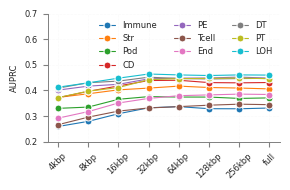

In [25]:
fig, ax = plt.subplots(figsize=FIGSIZE)
sns.lineplot(
    data=df_melted, x='Model', y='AUPRC', hue='Type',
    marker='o', markersize=MARKERSIZE, linewidth=LINEWIDTH,
    palette=palette, ax=ax, alpha=ALPHA
)

ax.set_xlabel('')

ax.set_ylabel('AUPRC', fontsize=LABEL_FONTSIZE)
ax.set_ylim(0.2, 0.7)

plt.xticks(rotation=45)
plt.legend(title='', title_fontsize=LEGEND_FONTSIZE, fontsize=LEGEND_FONTSIZE,
           frameon=False, shadow=True, loc='upper right', ncol=3)

ax.spines['left'].set_linewidth(SPINE_WIDTH)
ax.spines['left'].set_color(SPINE_COLOR)
ax.spines['bottom'].set_linewidth(SPINE_WIDTH)
ax.spines['bottom'].set_color(SPINE_COLOR)

ax.tick_params(axis='both', which='major', labelsize=TICK_FONTSIZE,
               bottom=True, left=True, top=False, right=False, color=TICK_COLOR)

ax.grid(True, alpha=GRID_ALPHA, linestyle=GRID_LINESTYLE, linewidth=GRID_LINEWIDTH)
sns.despine(top=True, right=True, left=False, bottom=False)
plt.tight_layout()
plt.show()